In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:/Users/Bhumika Chandan/Downloads/Dataset .csv")
print(df.head())

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [4]:
print (df.shape)
print(df.info())
print (df.columns)
print(df.isnull().sum())

(9551, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu 

In [5]:
print(df["Cuisines"].head(10))

0            French, Japanese, Desserts
1                              Japanese
2      Seafood, Asian, Filipino, Indian
3                       Japanese, Sushi
4                      Japanese, Korean
5                               Chinese
6                       Asian, European
7    Seafood, Filipino, Asian, European
8               European, Asian, Indian
9                              Filipino
Name: Cuisines, dtype: str


In [6]:
df["Cuisines"] = df["Cuisines"].fillna("")

df["Cuisines"] = df["Cuisines"].str.strip()

In [7]:
df["Cuisines"] = df["Cuisines"].str.split(",")

print(df["Cuisines"].head())

0           [French,  Japanese,  Desserts]
1                               [Japanese]
2    [Seafood,  Asian,  Filipino,  Indian]
3                       [Japanese,  Sushi]
4                      [Japanese,  Korean]
Name: Cuisines, dtype: object


In [8]:
cuisine_df = df.explode("Cuisines")

print(cuisine_df[["Restaurant ID", "Cuisines"]].head(10))

   Restaurant ID   Cuisines
0        6317637     French
0        6317637   Japanese
0        6317637   Desserts
1        6304287   Japanese
2        6300002    Seafood
2        6300002      Asian
2        6300002   Filipino
2        6300002     Indian
3        6318506   Japanese
3        6318506      Sushi


In [9]:
cuisine_df["Cuisines"] = (
    cuisine_df["Cuisines"].str.strip()
)

cuisine_df = cuisine_df[
    cuisine_df["Cuisines"] != ""
]

In [10]:
cuisine_count = (
    cuisine_df.groupby("Cuisines")["Restaurant ID"]
    .nunique()
    .sort_values(ascending=False)
)

print(cuisine_count.head(10))

Cuisines
North Indian    3960
Chinese         2733
Fast Food       1986
Mughlai          994
Italian          764
Bakery           744
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: Restaurant ID, dtype: int64


In [11]:
top_3_cuisines = cuisine_count.head(3)

print("Top 3 Cuisines:")
print(top_3_cuisines)

Top 3 Cuisines:
Cuisines
North Indian    3960
Chinese         2733
Fast Food       1986
Name: Restaurant ID, dtype: int64


In [12]:
total_restaurants = df["Restaurant ID"].nunique()

print("Total Restaurants:", total_restaurants)

Total Restaurants: 9551


In [13]:
percentage = (
    top_3_cuisines / total_restaurants
) * 100

print(percentage.round(2))

Cuisines
North Indian    41.46
Chinese         28.61
Fast Food       20.79
Name: Restaurant ID, dtype: float64


In [14]:
result = pd.DataFrame({
    "Restaurant Count": top_3_cuisines,
    "Percentage": percentage.round(2)
})

print(result)

              Restaurant Count  Percentage
Cuisines                                  
North Indian              3960       41.46
Chinese                   2733       28.61
Fast Food                 1986       20.79


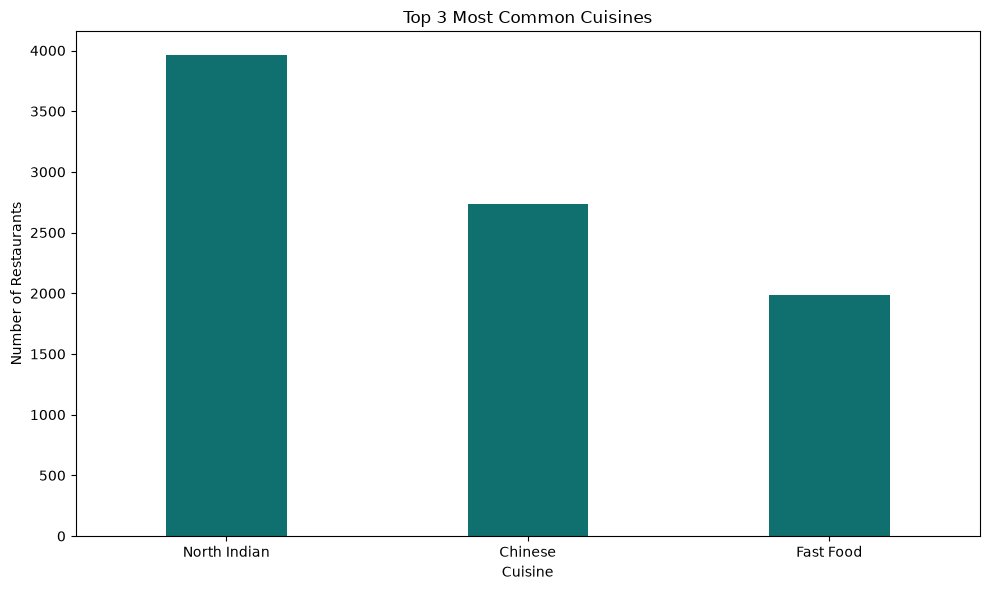

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_3_cuisines.index,
    y=top_3_cuisines.values,
    color="teal",
    width=0.4
)

plt.title("Top 3 Most Common Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.savefig("Top_Cuisines_Chart.png", dpi=300)
plt.show()

In [17]:
result.to_csv("Top_Cuisines_Analysis.csv")

print("Task 1 completed successfully!")

Task 1 completed successfully!
